In [1]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.circuit.library import RXGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit.primitives import StatevectorEstimator

import numpy as np
from numpy import pi

from itertools import product

from matplotlib import pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

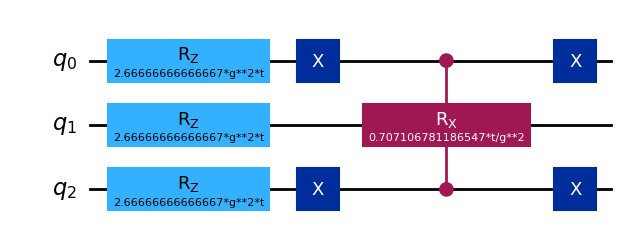

In [3]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_new(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        controlled_rx = RXGate(theta_B/N).control(2)  # 2 control qubits
        qc.append(controlled_rx, [i - 1, i + 1, i])

        qc.x(i - 1)
        qc.x(i + 1)
        
    return qc

def N_steps_compose_new(n, N):
    one_step_circuit = one_step_new(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 3
N = 1
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

In [11]:
observables_labels = ["IZI", "ZZI", "IZZ", "ZIZ"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [7]:
def plot_measurement_loop_new(n, N, t):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

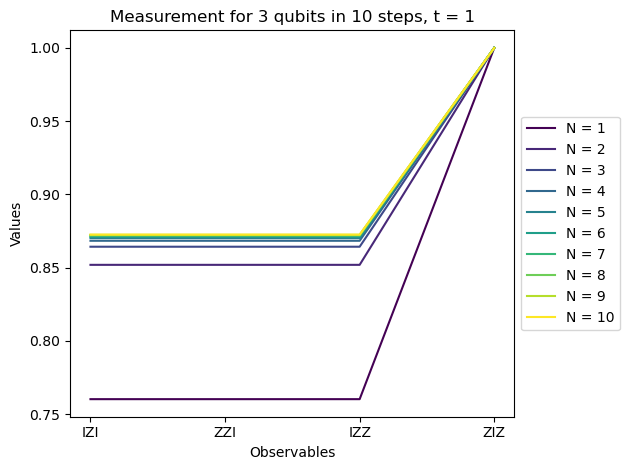

In [93]:
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors evenly spaced

for idx, i in enumerate(np.arange(1, 11)):
    labels, values = plot_measurement_loop_new(3, i, 1.0)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 10 steps, t = 1")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f't = 1, 10 Steps for 3 Qubits.png')
plt.show()

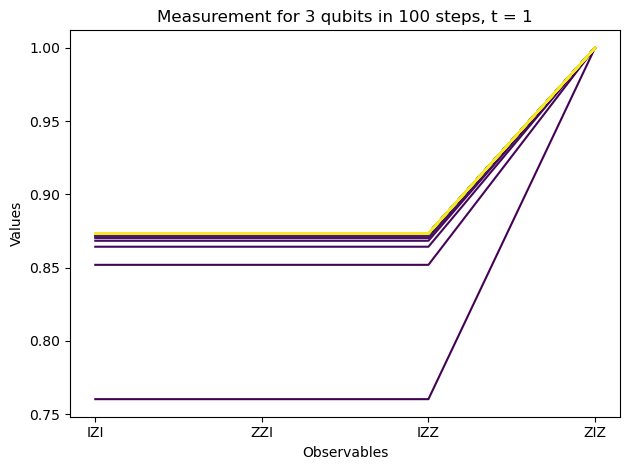

In [101]:
colors = cm.viridis(np.linspace(0, 1, 100))  # 10 colors evenly spaced

for idx, i in enumerate(np.arange(1, 101)):
    labels, values = plot_measurement_loop_new(3, i, 1.0)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 100 steps, t = 1")
plt.tight_layout()
plt.savefig(f't = 1, 100 Steps for 3 Qubits.png')
plt.show()

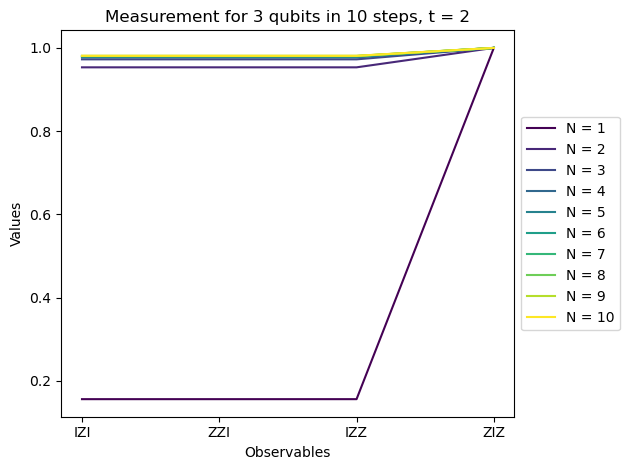

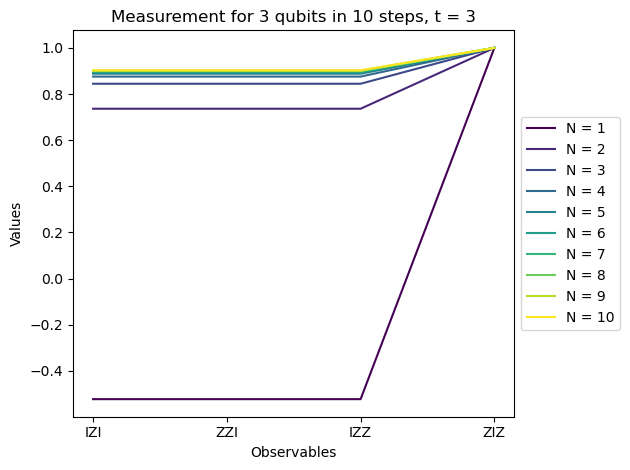

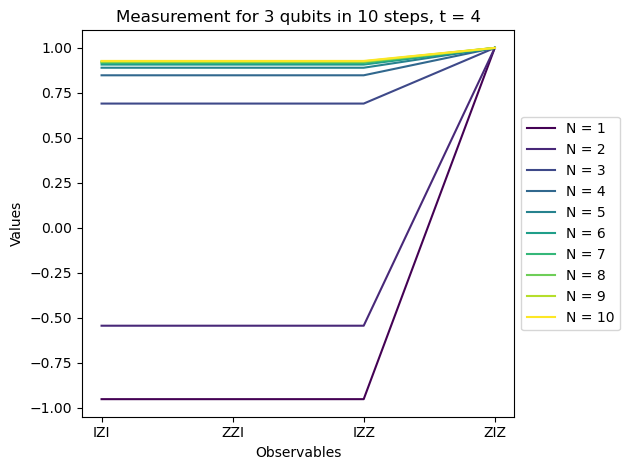

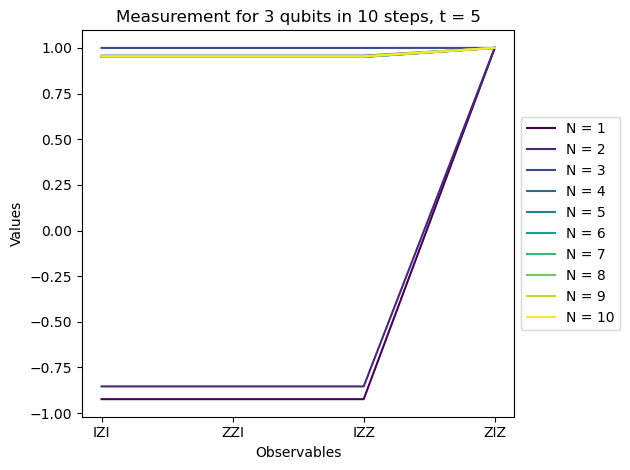

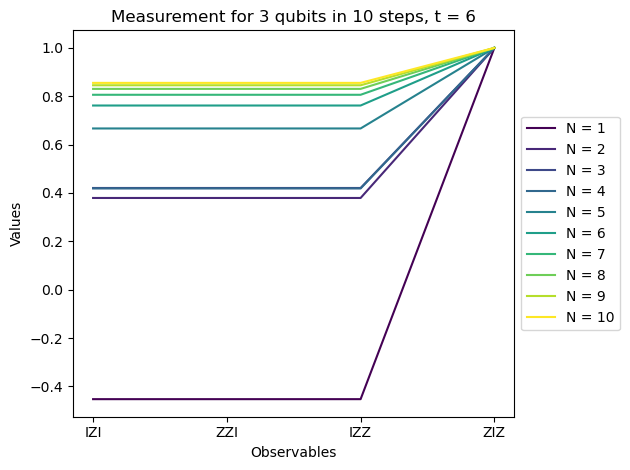

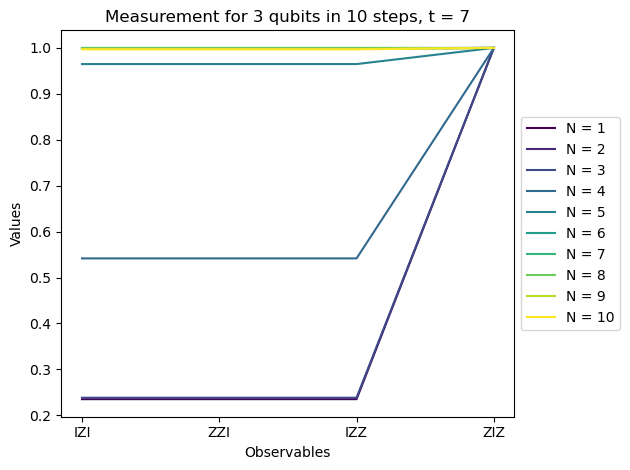

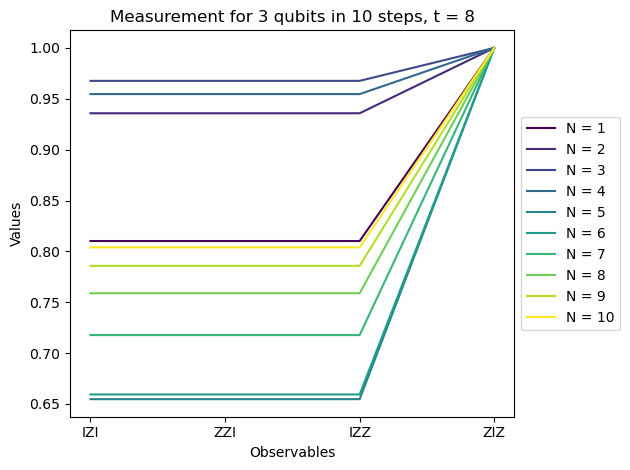

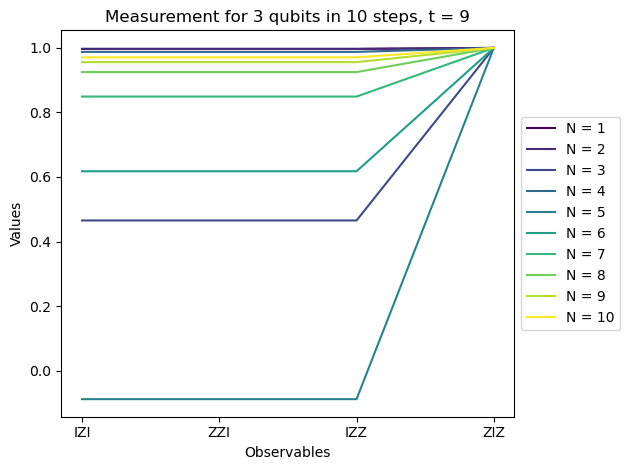

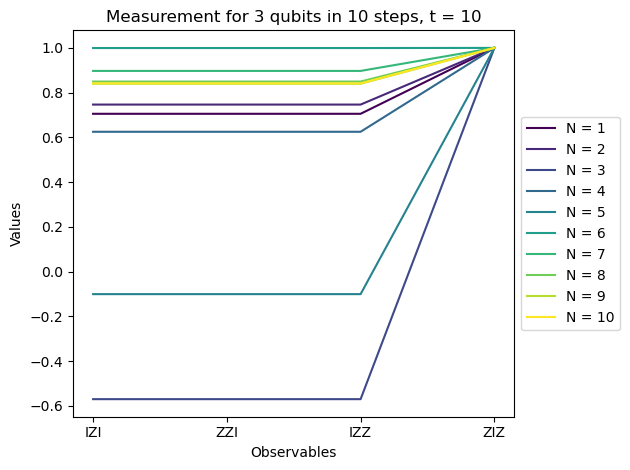

In [97]:
for j in np.arange(2.0, 11.0, 1.0):
    colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors evenly spaced

    for idx, i in enumerate(np.arange(1, 11)):
        labels, values = plot_measurement_loop_new(3, i, j)
        plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

    plt.xlabel("Observables")
    plt.ylabel("Values")
    plt.title(f"Measurement for 3 qubits in 10 steps, t = {int(j)}")
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    plt.tight_layout()
    plt.savefig(f't = {int(j)}, 10 Steps for 3 Qubits.png')
    plt.show()

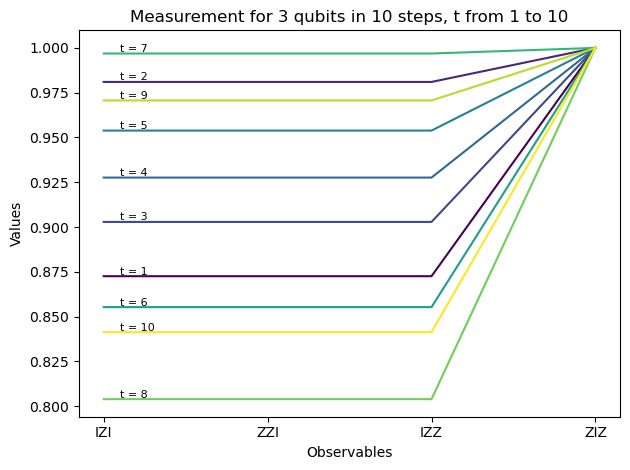

In [103]:
# Only N = 10 Steps for t from 1 to 10
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors

for idx, i in enumerate(np.arange(1.0, 11.0, 1.0)):
    labels, values = plot_measurement_loop_new(3, 10, i)
    plt.plot(labels, values, color=colors[idx])
    
    plt.text(
        x=0.1,
        y=values[0]+0.0025,
        s=f"t = {int(i)}",
        color='black',
        fontsize=8,
        va="center"
    )

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 10 steps, t from 1 to 10")
plt.tight_layout()
plt.show()

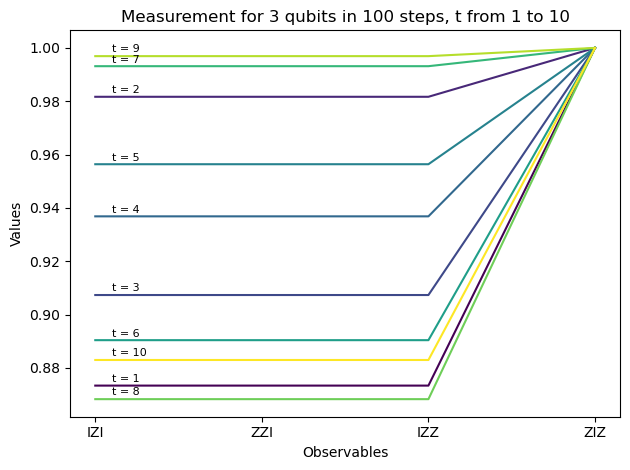

In [107]:
# Only N = 100 Steps for t from 1 to 10
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors

for idx, i in enumerate(np.arange(1.0, 11.0, 1.0)):
    labels, values = plot_measurement_loop_new(3, 100, i)
    plt.plot(labels, values, color=colors[idx])
    
    plt.text(
        x=0.1,
        y=values[0]+0.0025,
        s=f"t = {int(i)}",
        color='black',
        fontsize=8,
        va="center"
    )

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 100 steps, t from 1 to 10")
plt.tight_layout()
plt.show()

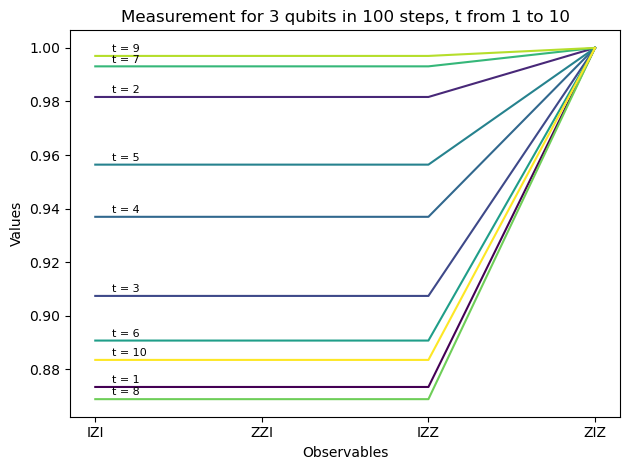

In [109]:
# Only N = 1000 Steps for t from 1 to 10
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors

for idx, i in enumerate(np.arange(1.0, 11.0, 1.0)):
    labels, values = plot_measurement_loop_new(3, 1000, i)
    plt.plot(labels, values, color=colors[idx])
    
    plt.text(
        x=0.1,
        y=values[0]+0.0025,
        s=f"t = {int(i)}",
        color='black',
        fontsize=8,
        va="center"
    )

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 100 steps, t from 1 to 10")
plt.tight_layout()
plt.show()